In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
## 1. Check the GPU
# We need a Tesla T4. Without a GPU, generation is too slow.
!nvidia-smi

Sat Nov 14 15:19:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Get our code from GitHub (branch `main`)
We delete any old copy so we always run the latest version.

In [3]:
%cd /kaggle/working
!rm -rf hlt-grpo-countdown
!git clone -b main https://github.com/hamasli/hlt-grpo-countdown.git
%cd hlt-grpo-countdown
!git log --oneline -3

/kaggle/working
Cloning into 'hlt-grpo-countdown'...
remote: Enumerating objects: 144, done.
remote: Counting objects: 100% (144/144), done.
remote: Compressing objects: 100% (92/92), done.
remote: Total 144 (delta 67), reused 119 (delta 43), pack-reused 0 (from 0)
Receiving objects: 100% (144/144), 604.82 KiB | 5.00 MiB/s, done.
Resolving deltas: 100% (67/67), done.
/kaggle/working/hlt-grpo-countdown
6d396c6 (HEAD -> main, origin/main, origin/HEAD) prompt v3: now added the equation variable between tags, like this <answer> equation </answer>
2cabb56 resolved the erorr of prompt, updated the prompt
87f7f00 Steps A-B: new data, tests, prompts, evaluate, trick baselines


## 3. Generate the data and test the verifier
Same seed (42) as on the laptop, so the puzzles are identical.
The tests must show 30 passed: if the verifier is wrong, all results are wrong.

In [4]:
!pip install -q pytest
!python -m src.data.generate
!python -m pytest -q

test     :   1000 puzzles, levels [2, 3] -> data/test.jsonl
test_ood :    500 puzzles, levels [4] -> data/test_ood.jsonl
val      :    200 puzzles, levels [2, 3] -> data/val.jsonl
train    :  10000 puzzles, levels [2, 3] -> data/train.jsonl
..............................                                           [100%]
30 passed in 0.11s


## 4. Trick baselines (no model)
The bar to beat: how many puzzles simple tricks and random equations solve.
Needed for the chart.

In [5]:
!python -m src.eval.trick_baselines
!python -m src.eval.trick_baselines --data data/test_ood.jsonl

trick                  2_numbers   3_numbers         all
target_in_numbers          0.00%       0.00%       0.00%
sum_all                   36.00%       5.40%      20.70%
product_all                2.40%       0.00%       1.20%
random_guess@1            52.40%      12.20%      32.30%
random_guess@4            78.60%      27.60%      53.10%
saved -> results/trick_baselines.json
trick                  4_numbers         all
target_in_numbers          0.00%       0.00%
sum_all                    1.00%       1.00%
product_all                0.00%       0.00%
random_guess@1             2.40%       2.40%
random_guess@4             6.80%       6.80%
saved -> results/trick_baselines_test_ood.json


## 5. Smoke test (32 puzzles)
A quick check that the model runs on the GPU before the full runs.
The accuracy here does not matter.

In [6]:
!python -m src.eval.evaluate --method cot --limit 32 --batch_size 32

config.json: 100%|█████████████████████████████| 659/659 [00:00<00:00, 3.06MB/s]
tokenizer_config.json: 100%|███████████████| 7.30k/7.30k [00:00<00:00, 24.7MB/s]
vocab.json: 100%|██████████████████████████| 2.78M/2.78M [00:00<00:00, 47.9MB/s]
merges.txt: 100%|███████████████████████████| 1.67M/1.67M [00:00<00:00, 111MB/s]
tokenizer.json: 100%|███████████████████████| 7.03M/7.03M [00:00<00:00, 146MB/s]

model.safetensors: downloading bytes:                       | 4.70MB            
model.safetensors: downloading bytes: ███▍                  |  156MB, 10.9MB/s  
model.safetensors: downloading bytes: ██████▋               |  301MB, 24.1MB/s  
model.safetensors: downloading bytes: █████████             |  410MB, 32.9MB/s  
model.safetensors: downloading bytes: ███████████▊          |  533MB, 44.1MB/s  
model.safetensors: downloading bytes: ██████████████▏       |  640MB, 53.5MB/s  
model.safetensors: downloading bytes: █████████████████     |  764MB, 63.7MB/s  
model.safetensors: download

## 6. Full baselines (~15 min)
For each model and method: the test set (1,000 puzzles: 2 and 3 numbers)
and the OOD test (500 puzzles: 4 numbers).
Max length: 64 tokens for zero-shot, 256 for CoT (the same as training).

In [32]:
models = ["Qwen/Qwen2.5-0.5B-Instruct", "Qwen/Qwen2.5-1.5B-Instruct"]
for m in models:
    for method in ["zero_shot", "cot"]:
        for data in ["data/test.jsonl", "data/test_ood.jsonl"]:
            print(f"\n===== {m} | {method} | {data} =====")
            !python -m src.eval.evaluate --model {m} --method {method} --data {data} --batch_size 32


===== Qwen/Qwen2.5-0.5B-Instruct | zero_shot | data/test.jsonl =====
Loading weights: 100%|███████████████████████| 290/290 [00:00<00:00, 661.89it/s]
model=Qwen/Qwen2.5-0.5B-Instruct method=zero_shot data=data/test.jsonl device=cuda puzzles=1000 samples_per_puzzle=1 max_new_tokens=64
  32/1000 done
  64/1000 done
  96/1000 done
  128/1000 done
  160/1000 done
  192/1000 done
  224/1000 done
  256/1000 done
  288/1000 done
  320/1000 done
  352/1000 done
  384/1000 done
  416/1000 done
  448/1000 done
  480/1000 done
  512/1000 done
  544/1000 done
  576/1000 done
  608/1000 done
  640/1000 done
  672/1000 done
  704/1000 done
  736/1000 done
  768/1000 done
  800/1000 done
  832/1000 done
  864/1000 done
  896/1000 done
  928/1000 done
  960/1000 done
  992/1000 done
  1000/1000 done
{
  "model": "Qwen/Qwen2.5-0.5B-Instruct",
  "adapter": null,
  "method": "zero_shot",
  "data": "data/test.jsonl",
  "num_samples": 1,
  "temperature": null,
  "max_new_tokens": 64,
  "device": "Tesla T4

## 7. Results table + chart
Accuracy for each model and method, by level (2, 3, 4 numbers),
next to one random equation as the reference to beat.
Saved as results/baseline_accuracy.png for the slides.

run                            2 numbers         3 numbers   4 numbers (OOD)
0.5B Zero-shot                      0.0%              0.0%              0.2%
0.5B CoT                            7.6%              1.6%              0.2%
1.5B Zero-shot                      0.2%              0.0%              0.0%
1.5B CoT                           26.4%              3.0%              0.4%
One random equation                52.4%             12.2%              2.4%


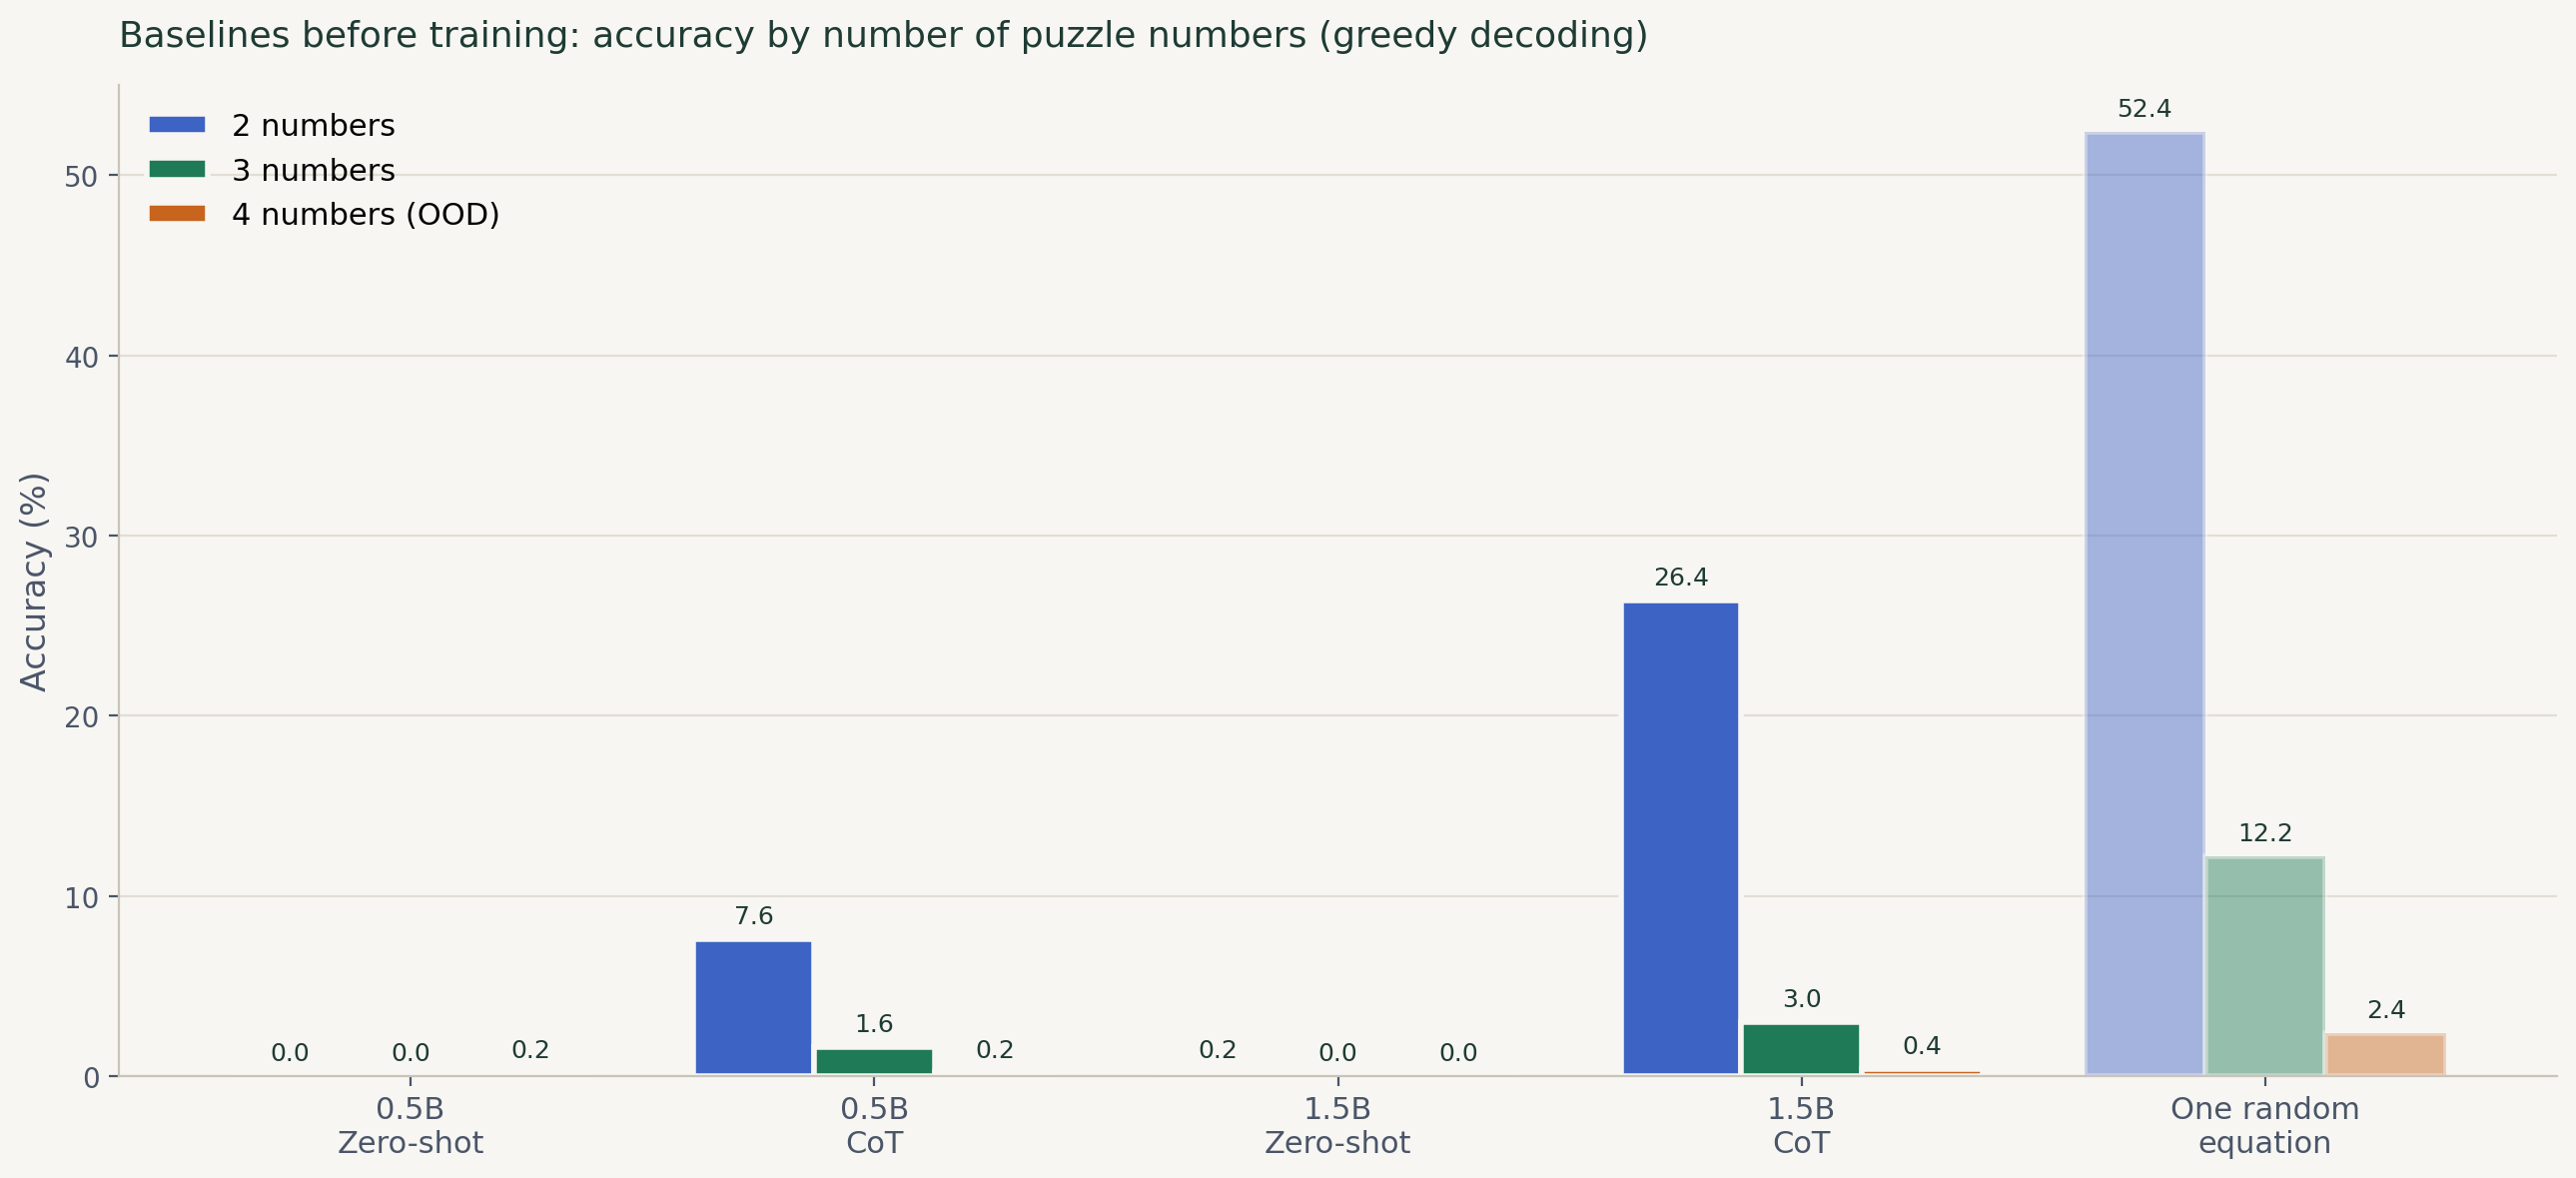

saved -> results/baseline_accuracy.png


In [33]:
import json, os
import matplotlib.pyplot as plt

R = "results"
RUNS = [("0.5B", "zero_shot", "0.5B\nZero-shot"), ("0.5B", "cot", "0.5B\nCoT"),
        ("1.5B", "zero_shot", "1.5B\nZero-shot"), ("1.5B", "cot", "1.5B\nCoT")]
LEVELS = [("2_numbers", "2 numbers", ""), ("3_numbers", "3 numbers", ""), ("4_numbers", "4 numbers (OOD)", "_test_ood")]
COLORS = ["#3D63C4", "#1F7A57", "#C8641E"]          # colorblind-checked; values printed on bars

def load(path):
    return json.load(open(path)) if os.path.exists(path) else {}

# 1) collect accuracy: rows = runs (+ random guess), columns = levels
names = [r[2] for r in RUNS] + ["One random\nequation"]
acc = {lv: [] for lv, _, _ in LEVELS}
for size, method, _ in RUNS:
    for lv, _, suffix in LEVELS:
        s = load(f"{R}/Qwen2.5-{size}-Instruct_{method}{suffix}_summary.json")
        acc[lv].append(s.get(lv, {}).get("accuracy", float("nan")))
tricks = {**load(f"{R}/trick_baselines.json").get("random_guess@1", {}),
          **load(f"{R}/trick_baselines_test_ood.json").get("random_guess@1", {})}
for lv, _, _ in LEVELS:
    acc[lv].append(tricks.get(lv, float("nan")))

# 2) table
print(f"{'run':<22}" + "".join(f"{lab:>18}" for _, lab, _ in LEVELS))
for i, n in enumerate(names):
    print(f"{n.replace(chr(10), ' '):<22}" + "".join(f"{acc[lv][i]:>17.1f}%" for lv, _, _ in LEVELS))

# 3) grouped bar chart
fig, ax = plt.subplots(figsize=(13, 6), dpi=200)
fig.patch.set_facecolor("#F7F6F2"); ax.set_facecolor("#F7F6F2")
w = 0.26
for j, (lv, lab, _) in enumerate(LEVELS):
    xs = [i + (j - 1) * w for i in range(len(names))]
    bars = ax.bar(xs, acc[lv], width=w, color=COLORS[j], label=lab, edgecolor="#F7F6F2", linewidth=2)
    for b, v in zip(bars, acc[lv]):
        if v == v:  # skip NaN
            ax.text(b.get_x() + b.get_width() / 2, v + 0.6, f"{v:.1f}", ha="center",
                    va="bottom", fontsize=9, color="#1E3B34")
    bars[-1].set_alpha(0.45)  # random guess = reference, faded
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, fontsize=11, color="#1E3B34")
ax.set_ylabel("Accuracy (%)", fontsize=12, color="#4A5568")
ax.set_title("Baselines before training: accuracy by number of puzzle numbers (greedy decoding)",
             fontsize=13, color="#1E3B34", loc="left", pad=14)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.spines["left"].set_color("#C9C4BA"); ax.spines["bottom"].set_color("#C9C4BA")
ax.tick_params(colors="#4A5568"); ax.yaxis.grid(True, color="#E2DED5"); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=11, loc="upper left")
plt.tight_layout()
plt.savefig(f"{R}/baseline_accuracy.png", facecolor=fig.get_facecolor())
plt.show()
print(f"saved -> {R}/baseline_accuracy.png")

This is a real finding (good for the report)
Small models are very sensitive to examples in the prompt: they copy the surface pattern.
This matches DeepSeek-R1’s limitation, “prompt sensitivity” (in our notes, section 2.9).
For the report: “Our first prompt contained a 3-number format example; the models copied its structure and invented numbers on 2-number puzzles (0% accuracy). We removed the numeric example and re-ran all baselines.”

## 8. Save the results
Zip the results folder and download it (right panel → results.zip → ⋮ → Download),
then copy into the repo's results/ folder and commit.

In [35]:
%cd /kaggle/working
!zip -r -q results.zip hlt-grpo-countdown/results
!ls -lh results.zip

/kaggle/working
-rw-r--r-- 1 root root 347K Nov 14 17:20 results.zip


2. Confirm why zero-shot fails (1 minute, no GPU needed):

In [36]:
%cd /kaggle/working
!rm -rf hlt-grpo-countdown
!git clone -b main https://github.com/hamasli/hlt-grpo-countdown.git
%cd hlt-grpo-countdown
!git log --oneline -1                       # must show "verifier reads LaTeX..."
!rm -rf results && mkdir results            # start clean
!python -m src.data.generate
!python -m pytest -q                        # 32 passed
!python -m src.eval.trick_baselines
!python -m src.eval.trick_baselines --data data/test_ood.jsonl

/kaggle/working
Cloning into 'hlt-grpo-countdown'...
remote: Enumerating objects: 193, done.
remote: Counting objects: 100% (193/193), done.
remote: Compressing objects: 100% (109/109), done.
remote: Total 193 (delta 109), reused 156 (delta 73), pack-reused 0 (from 0)
Receiving objects: 100% (193/193), 1.05 MiB | 7.32 MiB/s, done.
Resolving deltas: 100% (109/109), done.
/kaggle/working/hlt-grpo-countdown
fc5b270 (HEAD -> main, origin/main, origin/HEAD) Final baselines: prompt v3 + LaTeX-aware verifier
test     :   1000 puzzles, levels [2, 3] -> data/test.jsonl
test_ood :    500 puzzles, levels [4] -> data/test_ood.jsonl
val      :    200 puzzles, levels [2, 3] -> data/val.jsonl
train    :  10000 puzzles, levels [2, 3] -> data/train.jsonl
................................                                         [100%]
32 passed in 0.11s
trick                  2_numbers   3_numbers         all
target_in_numbers          0.00%       0.00%       0.00%
sum_all                   36.00%       

In [37]:
!python -m src.eval.error_analysis

No *_outputs.jsonl files found. Run evaluate.py first.


Step D: pass@4 (CoT, both models, ~40 min). This decides the stages and confirms the model:

In [38]:
%cd /kaggle/working/hlt-grpo-countdown
for m in ["Qwen/Qwen2.5-0.5B-Instruct", "Qwen/Qwen2.5-1.5B-Instruct"]:
    print(f"\n===== {m} =====")
    !python -m src.eval.evaluate --model {m} --method cot --num_samples 4 --temperature 1.0 --batch_size 16

/kaggle/working/hlt-grpo-countdown

===== Qwen/Qwen2.5-0.5B-Instruct =====
Loading weights: 100%|███████████████████████| 290/290 [00:00<00:00, 590.04it/s]
model=Qwen/Qwen2.5-0.5B-Instruct method=cot data=data/test.jsonl device=cuda puzzles=1000 samples_per_puzzle=4 max_new_tokens=256
  16/1000 done
  32/1000 done
  48/1000 done
  64/1000 done
  80/1000 done
  96/1000 done
  112/1000 done
  128/1000 done
  144/1000 done
  160/1000 done
  176/1000 done
  192/1000 done
  208/1000 done
  224/1000 done
  240/1000 done
  256/1000 done
  272/1000 done
  288/1000 done
  304/1000 done
  320/1000 done
  336/1000 done
  352/1000 done
  368/1000 done
  384/1000 done
  400/1000 done
  416/1000 done
  432/1000 done
  448/1000 done
  464/1000 done
  480/1000 done
  496/1000 done
  512/1000 done
  528/1000 done
  544/1000 done
  560/1000 done
  576/1000 done
  592/1000 done
  608/1000 done
  624/1000 done
  640/1000 done
  656/1000 done
  672/1000 done
  688/1000 done
  704/1000 done
  720/1000 done


In [39]:
%cd /kaggle/working/hlt-grpo-countdown
!ls results | grep k4
!find /kaggle/working -name "*k4*"

/kaggle/working/hlt-grpo-countdown
Qwen2.5-0.5B-Instruct_cot_k4_samples.jsonl
Qwen2.5-0.5B-Instruct_cot_k4_summary.json
Qwen2.5-1.5B-Instruct_cot_k4_samples.jsonl
Qwen2.5-1.5B-Instruct_cot_k4_summary.json
/kaggle/working/hlt-grpo-countdown/results/Qwen2.5-0.5B-Instruct_cot_k4_summary.json
/kaggle/working/hlt-grpo-countdown/results/Qwen2.5-1.5B-Instruct_cot_k4_samples.jsonl
/kaggle/working/hlt-grpo-countdown/results/Qwen2.5-1.5B-Instruct_cot_k4_summary.json
/kaggle/working/hlt-grpo-countdown/results/Qwen2.5-0.5B-Instruct_cot_k4_samples.jsonl
